<a href="https://colab.research.google.com/github/ibuscio/taller_deeplearning/blob/loss_lens/tarea_losslens_imp.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tarea: el paisaje de pérdida de tu propia red

En esta tarea vas a usar **losslens** para visualizar la función de pérdida alrededor de una red que
**entrenaste en una tarea anterior**, y a explicar lo que ves.

No necesitas saber cómo funciona losslens por dentro. Solo necesitas estas llamadas:

```python
surf = losslens.surface(model, data, loss_fn=nn.CrossEntropyLoss())   # calcular
surf.plot()   surf.plot_3d()   surf.plot_slice()                      # visualizar
surf.summary()                                                        # números
losslens.compare({"A": surf_a, "B": surf_b})                          # comparar
surf.save("a.npz");  surf = losslens.load("a.npz")                    # guardar
```

Documentación completa: https://github.com/iturbideM/losslens

**Qué entregar:** este notebook, ejecutado de principio a fin, con cada *Tu respuesta aquí*
reemplazado por tu respuesta. Las respuestas deben ser breves (unas pocas oraciones) y hacer
referencia a tus gráficas y números.

**Consejos**

- Usa un entorno con GPU (en Colab: *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU*).
- Prueba primero con una `resolution` baja (por ejemplo 11) para verificar que todo funciona, y luego
  usa el valor por defecto para tus figuras finales.
- Pásale a losslens datos **sin aumento de datos** (*data augmentation*).
- Guarda cada superficie que calcules con `surf.save(...)`, por si el notebook se reinicia.

## Preparación

In [1]:
!pip install torchinfo

In [2]:
%pip install -q git+https://github.com/iturbideM/losslens

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import losslens
import torch.optim as optim
from torchinfo import summary

# Verificar si CUDA está disponible

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## Parte 1: Tu modelo y tus datos

Carga (o vuelve a entrenar) la red de tu tarea anterior y los datos con los que fue entrenada.

1. Define la clase de tu modelo y carga sus pesos entrenados.
2. Construye un DataLoader, un Dataset o tensores `(X, y)` con tus datos de **entrenamiento**, sin
   aumento de datos.
3. Escribe la función de pérdida con la que entrenaste.

Si tus batches no son de la forma `(inputs, targets)`, o tu pérdida no es
`loss_fn(model(inputs), targets)`, vas a necesitar `forward=` en lugar de `loss_fn=` (ver la
documentación).

##Modelo

In [4]:
# Modelo: Arquitectura DenseNet

# 1. Capa individual de un Bloque Denso:
#    Pre-activación (BatchNorm2d -> ReLU -> Conv2d 3x3 con padding=1 y bias=False)
#    y concatenación en la dimensión de canales (dim=1)
class DenseLayer(nn.Module):
    def __init__(self, in_channels, growth_rate):
        super(DenseLayer, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, growth_rate, kernel_size=3, padding=1, bias=False)

    def forward(self, x):
        y = self.conv(self.relu(self.bn(x)))
        # Concatenamos entrada (x) y salida (y) a lo largo de los canales [N, C, H, W]
        return torch.cat([x, y], dim=1)


# 2. Bloque Denso:
#    Conecta varias DenseLayer en serie. Mantiene alto y ancho;
#    cada capa agrega `growth_rate` canales nuevos: C -> C + k -> C + 2k ...
class DenseBlock(nn.Module):
    def __init__(self, num_convs, in_channels, growth_rate):
        super(DenseBlock, self).__init__()
        layers = []
        for i in range(num_convs):
            layers.append(DenseLayer(in_channels + i * growth_rate, growth_rate))
        self.net = nn.Sequential(*layers)
        self.out_channels = in_channels + num_convs * growth_rate

    def forward(self, x):
        return self.net(x)


# 3. Bloque de Transición:
#    Entre bloques densos, reduce la cantidad de canales (Conv 1x1)
#    y reduce a la mitad el alto y el ancho (AvgPool2d 2x2)
class TransitionBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super(TransitionBlock, self).__init__()
        self.bn = nn.BatchNorm2d(in_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv = nn.Conv2d(in_channels, out_channels, kernel_size=1, bias=False)
        self.pool = nn.AvgPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.pool(self.conv(self.relu(self.bn(x))))


# 4. Red completa DenseNet (las 4 partes principales)
class DenseNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=10, num_channels=32, growth_rate=16, arch=(4, 4, 4, 4)):
        super(DenseNet, self).__init__()

        # Parte 1: Convolución inicial (extrae las primeras características)
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, num_channels, kernel_size=7, stride=2, padding=3, bias=False), # 128x128 -> 64x64
            nn.BatchNorm2d(num_channels),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)                                      # 64x64 -> 32x32
        )

        # Partes 2 y 3: Bloques densos intercalados con Transiciones
        blocks = []
        channels = num_channels
        for i, num_convs in enumerate(arch):
            block = DenseBlock(num_convs, channels, growth_rate)
            blocks.append(block)
            channels = block.out_channels
            # Agregamos transición entre bloques (excepto después del último bloque denso)
            if i != len(arch) - 1:
                blocks.append(TransitionBlock(channels, channels // 2))
                channels = channels // 2

        self.features = nn.Sequential(*blocks)

        # Parte 4: Capa de salida (Pooling global + capa completamente conectada)
        self.bn_final = nn.BatchNorm2d(channels)
        self.relu_final = nn.ReLU(inplace=True)
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(channels, num_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.features(x)
        x = self.relu_final(self.bn_final(x))
        x = self.global_pool(x)
        x = x.flatten(start_dim=1)
        x = self.classifier(x)
        return x


# Instanciamos el modelo base DenseNet
torch.manual_seed(34)
model = DenseNet(in_channels=3, num_classes=10, num_channels=32, growth_rate=16, arch=(4, 4, 4, 4)).to(device)

In [5]:
summary(DenseNet(in_channels=3), input_size=(64, 3, 128, 128))

Layer (type:depth-idx)                        Output Shape              Param #
DenseNet                                      [64, 10]                  --
├─Sequential: 1-1                             [64, 32, 32, 32]          --
│    └─Conv2d: 2-1                            [64, 32, 64, 64]          4,704
│    └─BatchNorm2d: 2-2                       [64, 32, 64, 64]          64
│    └─ReLU: 2-3                              [64, 32, 64, 64]          --
│    └─MaxPool2d: 2-4                         [64, 32, 32, 32]          --
├─Sequential: 1-2                             [64, 124, 4, 4]           --
│    └─DenseBlock: 2-5                        [64, 96, 32, 32]          --
│    │    └─Sequential: 3-1                   [64, 96, 32, 32]          32,704
│    └─TransitionBlock: 2-6                   [64, 48, 16, 16]          --
│    │    └─BatchNorm2d: 3-2                  [64, 96, 32, 32]          192
│    │    └─ReLU: 3-3                         [64, 96, 32, 32]          --
│    │    └─

##Datos

In [6]:
import urllib.request
import tarfile
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# Descarga y preparación de Imagewoof (sin Data Augmentation)
data_dir = Path("data")
data_dir.mkdir(exist_ok=True)
archive_path = data_dir / "imagewoof2-160.tgz"
extracted_path = data_dir / "imagewoof2-160"

if not extracted_path.exists():
    if not archive_path.exists():
        print("Descargando imagewoof2-160...")
        url = "https://s3.amazonaws.com/fast-ai-imageclas/imagewoof2-160.tgz"
        urllib.request.urlretrieve(url, archive_path)
    print("Descomprimiendo imagewoof2-160...")
    with tarfile.open(archive_path, "r:gz") as tar:
        tar.extractall(data_dir)
    print("Dataset listo.")



Descargando imagewoof2-160...
Descomprimiendo imagewoof2-160...


/tmp/ipykernel_1929/202341846.py:20: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(data_dir)


Dataset listo.


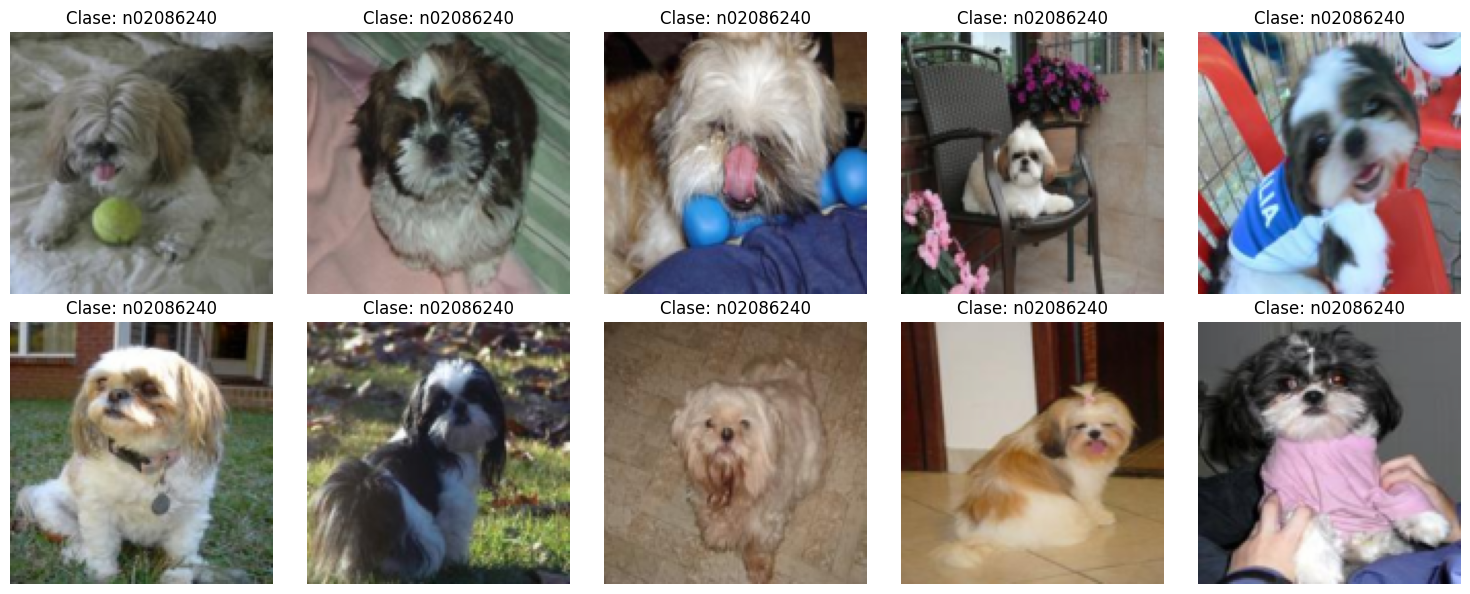

In [13]:
import matplotlib.pyplot as plt
import numpy as np

# Tomamos 10 imágenes del conjunto de entrenamiento
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
classes = train_full.classes

for i in range(10):
    img, label = train_full[i]

    # Desnormalizar la imagen para visualizarla correctamente
    img = img.permute(1, 2, 0).numpy()
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    img = std * img + mean
    img = np.clip(img, 0, 1)

    ax = axes[i // 5, i % 5]
    ax.imshow(img)
    ax.set_title(f"Clase: {classes[label]}")
    ax.axis('off')

plt.tight_layout()
plt.show()

##Transformación

In [7]:
# Transformaciones limpias SIN aumento de datos: solo resize y normalización
eval_transforms = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])



##DataLoader

In [8]:
train_full = datasets.ImageFolder(extracted_path / "train", transform=eval_transforms)
val_full = datasets.ImageFolder(extracted_path / "val", transform=eval_transforms)

# Para un cálculo eficiente y rápido de losslens, usamos un subset representativo de 1000 muestras
subset_indices = list(range(min(1000, len(train_full))))
train_subset = Subset(train_full, subset_indices)

train_loader = DataLoader(train_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(val_full, batch_size=64, shuffle=False)

print(f"Muestras de entrenamiento para losslens: {len(train_subset)}")
print(f"Muestras de test para evaluación: {len(val_full)}")

Muestras de entrenamiento para losslens: 1000
Muestras de test para evaluación: 3929


##Muestreo

In [9]:
# Muestreo estratificado balanceado: 100 muestras por cada una de las 10 clases (1000 muestras en total)
import numpy as np
targets = np.array(train_full.targets)
rng = np.random.default_rng(34)
subset_indices = []
for cls_idx in range(10):
    cls_positions = np.where(targets == cls_idx)[0]
    chosen = rng.choice(cls_positions, size=min(100, len(cls_positions)), replace=False)
    subset_indices.extend(chosen.tolist())
train_subset = Subset(train_full, subset_indices)
# DataLoader de entrenamiento completo con shuffle=True para aprender las 10 clases correctamente
train_fit_loader = DataLoader(train_full, batch_size=64, shuffle=True)
# DataLoader fijo y balanceado (sin aumento de datos ni shuffle) para evaluar losslens
train_loader = DataLoader(train_subset, batch_size=64, shuffle=False)
test_loader = DataLoader(val_full, batch_size=64, shuffle=False)
print(f"Muestras de entrenamiento totales: {len(train_full)}")
print(f"Muestras balanceadas para losslens: {len(train_subset)} (100 por clase)")
print(f"Muestras de test para evaluación: {len(val_full)}")

Muestras de entrenamiento totales: 9025
Muestras balanceadas para losslens: 1000 (100 por clase)
Muestras de test para evaluación: 3929


##Función de pérdida

In [10]:

# Función de pérdida estándar para clasificación multiclase
criterion = nn.CrossEntropyLoss()
# Función de entrenamiento rápida
def train_model(net, loader, epochs=6, lr=0.001, weight_decay=0.0):
    optimizer = optim.Adam(net.parameters(), lr=lr, weight_decay=weight_decay)
    net.train()
    for ep in range(epochs):
        total_loss, correct, total = 0.0, 0, 0
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            optimizer.zero_grad()
            out = net(x_b)
            loss = criterion(out, y_b)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * x_b.size(0)
            preds = out.argmax(dim=1)
            correct += (preds == y_b).sum().item()
            total += x_b.size(0)
        print(f"Época {ep+1:02d}/{epochs:02d} | Train Loss: {total_loss/total:.4f} | Acc: {correct/total*100:.2f}%")
    return net

# Entrenamos el modelo base (o cargamos si ya existía guardado)
weights_path = Path("DenseNet_base.pth")
if weights_path.exists():
    print("Cargando pesos preentrenados del modelo base...")
    model.load_state_dict(torch.load(weights_path, map_location=device))
else:
    print("Entrenando modelo base (DenseNet sin regularización)...")
    model = train_model(model, train_loader, epochs=20, lr=0.001, weight_decay=0.0)
    torch.save(model.state_dict(), weights_path)
    print("Pesos guardados en DenseNet_base.pth")


Entrenando modelo base (DenseNet sin regularización)...
Época 01/20 | Train Loss: 2.4916 | Acc: 2.10%
Época 02/20 | Train Loss: 2.3559 | Acc: 4.10%
Época 03/20 | Train Loss: 2.3232 | Acc: 7.00%
Época 04/20 | Train Loss: 2.3086 | Acc: 7.40%
Época 05/20 | Train Loss: 2.3004 | Acc: 8.70%
Época 06/20 | Train Loss: 2.2974 | Acc: 5.90%
Época 07/20 | Train Loss: 2.3032 | Acc: 7.60%
Época 08/20 | Train Loss: 2.3033 | Acc: 9.10%
Época 09/20 | Train Loss: 2.2877 | Acc: 8.00%
Época 10/20 | Train Loss: 2.2810 | Acc: 9.70%
Época 11/20 | Train Loss: 2.2723 | Acc: 11.10%
Época 12/20 | Train Loss: 2.2629 | Acc: 13.10%
Época 13/20 | Train Loss: 2.2590 | Acc: 13.50%
Época 14/20 | Train Loss: 2.2530 | Acc: 13.00%
Época 15/20 | Train Loss: 2.2402 | Acc: 15.30%
Época 16/20 | Train Loss: 2.2241 | Acc: 18.80%
Época 17/20 | Train Loss: 2.2188 | Acc: 18.00%
Época 18/20 | Train Loss: 2.2255 | Acc: 16.90%
Época 19/20 | Train Loss: 2.2218 | Acc: 19.40%
Época 20/20 | Train Loss: 2.1856 | Acc: 24.80%
Pesos guardado

## Parte 2: El paisaje de tu modelo

Calcula el paisaje alrededor de tu modelo entrenado con las opciones por defecto, y muestra la
gráfica de contorno, la gráfica 3D y los cortes. Luego imprime el resumen.

In [11]:

# Calculamos el paisaje de pérdida con las opciones por defecto
# Usamos resolution=15 para calcular rápido y con buena definición
surf = losslens.surface(model, train_loader, loss_fn=criterion, resolution=15)
surf.save("surf_base.npz")
print("Superficie calculada y guardada en surf_base.npz")


Evaluating 225 points on 1000 examples (estimated time: 11 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

Superficie calculada y guardada en surf_base.npz


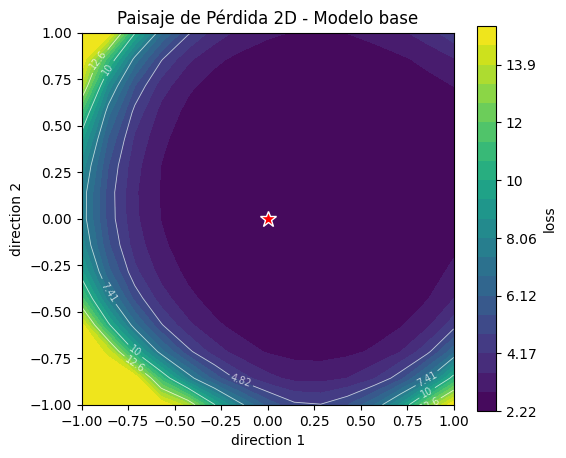

In [14]:
# Gráfica de contorno
# Gráfica de contorno 2D
surf.plot(title="Paisaje de Pérdida 2D - Modelo base")


In [15]:
# Gráfica 3D
# Gráfica interactiva 3D
surf.plot_3d(title="Paisaje de Pérdida 3D - Modelo Base")


In [16]:
# Cargar tu propia superficie guardada 'surf_base.npz' en lugar de un archivo inexistente
surf_base_cargado = losslens.load("surf_base.npz")
surf_base_cargado.plot_3d(log=True, zmax=10, title="losslens: Mi Modelo Base (Cargado)")

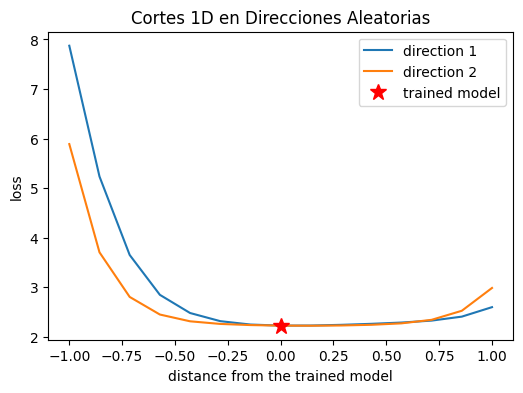

In [17]:
# Cortes
# Cortes 1D a través del mínimo en ambas direcciones
surf.plot_slice(title="Cortes 1D en Direcciones Aleatorias")


## Resumen

In [18]:

# Resumen cuantitativo de la superficie
resumen_base = surf.summary()
resumen_base


DenseNet  (scale=1.0, 1000 examples)
  loss of the trained model                     2.226
  lowest loss on the grid                       2.223
  where it is (direction 1, direction 2)        (+0.00, +0.14)
  is the trained model the lowest point?        no
  mean loss increase at 10% of scale            0.007212
  mean loss increase at 25% of scale            0.03139
  mean loss increase at 50% of scale            0.175
  steeper / flatter direction, at 50% of scale  2.614


{'center_loss': 2.2257434558868407,
 'grid_min_loss': 2.223408597946167,
 'grid_min_at': (0.0, 0.1428571428571428),
 'min_is_center': False,
 'rise_at_10%': 0.0072118107137786325,
 'rise_at_25%': 0.03138575757251605,
 'rise_at_50%': 0.17503423537537177,
 'asymmetry': 2.614016234778538}

**2.1** Describe la forma del paisaje. ¿Está el modelo entrenado en el fondo de un valle? ¿El
valle es ancho o angosto, redondo o alargado, suave o irregular?

El paisaje de pérdida muestra una cuenca suave pero ligeramente **alargada (elíptica)**, en la cual el modelo entrenado se encuentra **muy cerca del fondo del valle, aunque todavía no exactamente en el mínimo absoluto**:

* **Ubicación respecto al fondo del valle:** El modelo entrenado está en `(0.00, 0.00)` con una pérdida muy próxima al fondo, mientras que el punto más bajo de la grilla se ubica apenas a un paso de distancia, en las coordenadas **`(+0.00, +0.14)`** (`is the trained model the lowest point? no`). Esto indica que el optimizador llegó prácticamente a la base de la cuenca, quedando en una pendiente sumamente leve a punto de converger.
* **Ancho y suavidad:** El valle es **ancho y suave**, sin picos abruptos, barreras ni irregularidades caóticas; las curvas de nivel se abren de forma gradual alrededor de la zona central.
* **Forma (redondo vs. alargado):** Los contornos tienen una forma **moderadamente alargada (elíptica)**: la pérdida sube más rápido a lo largo de una dirección que de la otra, formando un canal o valle ovalado en lugar de un círculo perfecto.

**2.2** Usa los números de `summary()` para respaldar tu descripción.

* **Casi en el fondo del valle (`min_is_center: False`):** La pérdida del modelo entrenado en `(0.00, 0.00)` es **`2.226`**, prácticamente idéntica a la pérdida mínima de toda la cuadrícula (**`2.223`**), que se encuentra apenas desplazada un paso en la segunda dirección: **`(+0.00, +0.14)`** (una diferencia de solo `0.0023`).
* **Valle ancho y de pendiente suave:** Al alejarnos del centro un 10% y un 25% de la escala, la pérdida promedio aumenta apenas **`0.007212`** y **`0.03139`** respectivamente. Incluso al 50% de la escala, el incremento medio es de solo **`0.175`**, lo que confirma cuantitativamente una superficie suave y sin paredes abruptas cercanas.
* **Valle alargado / asimétrico (`asymmetry: 2.614`):** La relación entre la dirección más empinada y la más plana al 50% de la escala es de **`2.614`**. Al ser mayor que `1.0` (la dirección más empinada sube ~2.6 veces más rápido que la más plana), respalda que los contornos del valle tengan forma elíptica/alargada.

## Parte 3: ¿Es una forma real?

Las dos direcciones son aleatorias. Calcula el paisaje de nuevo con otra `seed`, y compara ambos
con `losslens.compare`.

Evaluating 225 points on 1000 examples (estimated time: 11 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

                                              Seed por defecto          Seed 123
loss of the trained model                                2.226             2.226
lowest loss on the grid                                  2.223             2.225
where it is (direction 1, direction 2)          (+0.00, +0.14)    (+0.14, +0.00)
is the trained model the lowest point?                      no                no
mean loss increase at 10% of scale                    0.007212          0.009701
mean loss increase at 25% of scale                     0.03139           0.03948
mean loss increase at 50% of scale                       0.175            0.1886
steeper / flatter direction, at 50% of scale             2.614             1.349


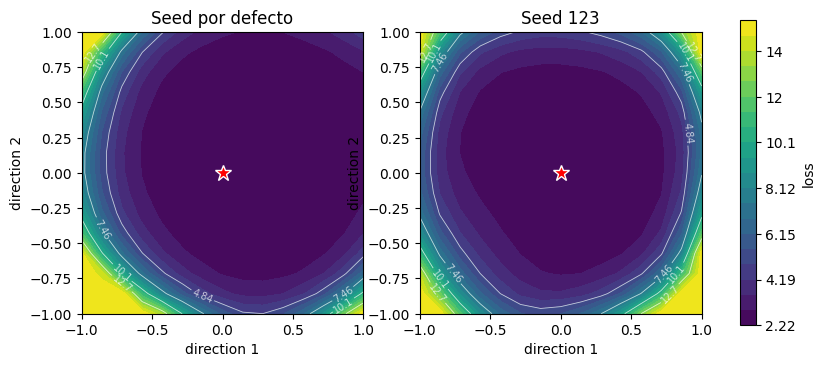

In [19]:
# Segunda semilla y comparación
# Calculamos el paisaje con otra semilla (otras dos direcciones aleatorias independientes)
surf_seed2 = losslens.surface(model, train_loader, loss_fn=criterion, seed=123, resolution=15)
surf_seed2.save("surf_seed2.npz")

# Comparamos ambas superficies lado a lado con la misma escala de color
losslens.compare({"Seed por defecto": surf, "Seed 123": surf_seed2})


**3.1** ¿Se parecen los dos paisajes? ¿Qué te dice eso sobre tu respuesta a la Parte 2?

Sí, ambos paisajes son muy consistentes en su estructura general y muestran la misma tendencia, aunque con una ligera variación en la simetría según el corte aleatorio elegido:

* **Ubicación respecto al mínimo:** En ambas semillas se confirma exactamente lo mismo: el modelo entrenado tiene una pérdida central de **`2.226`** y no está en el mínimo exacto (`no` en ambas), pero se ubica apenas a un paso de la cuadrícula del punto más bajo (**`2.223`** en `(+0.00, +0.14)` para la semilla por defecto y **`2.225`** en `(+0.14, +0.00)` para la `Seed 123`).
* **Ancho y pendiente del valle:** La tasa de aumento promedio de la pérdida es casi idéntica en ambas proyecciones en todas las escalas: sube **`0.007212` vs. `0.009701`** al 10%, **`0.03139` vs. `0.03948`** al 25%, y **`0.175` vs. `0.1886`** al 50% de la escala.
* **Forma y asimetría:** Mientras que la semilla por defecto capturó una dirección más alargada (asimetría de **`2.614`**), la `Seed 123` muestra contornos bastante más redondos (asimetría de **`1.349`**).


Confirma que las conclusiones principales de la **Parte 2** (que el modelo está muy cerca de la base de una cuenca ancha, suave y sin irregularidades bruscas) reflejan una **propiedad geométrica real del punto de convergencia** en el espacio de parámetros y no un artefacto azaroso de las dos primeras direcciones elegidas, si bien el grado de elongación del valle varía moderadamente según el plano de corte (`2.614` vs. `1.349`).

## Parte 4: Acercar y alejar

Calcula el paisaje con al menos otros dos valores de `scale`, uno menor y otro mayor que 1.0, y
grafícalos.

Evaluating 225 points on 1000 examples (estimated time: 12 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

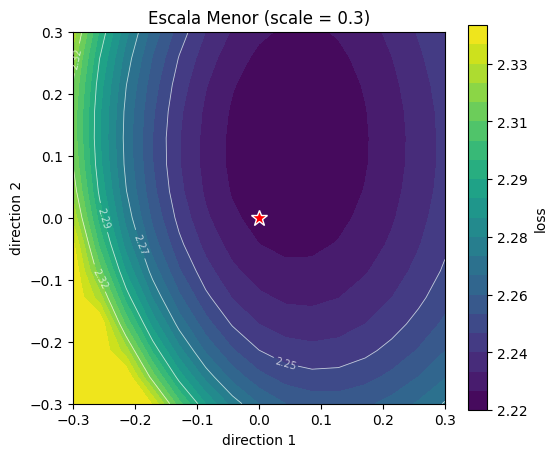

In [20]:
# Escala menor
# Escala chica: miramos con lupa el entorno inmediato
surf_small = losslens.surface(model, train_loader, loss_fn=criterion, scale=0.3, resolution=15)
surf_small.save("surf_small.npz")
surf_small.plot(title="Escala Menor (scale = 0.3)")


Evaluating 225 points on 1000 examples (estimated time: 12 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

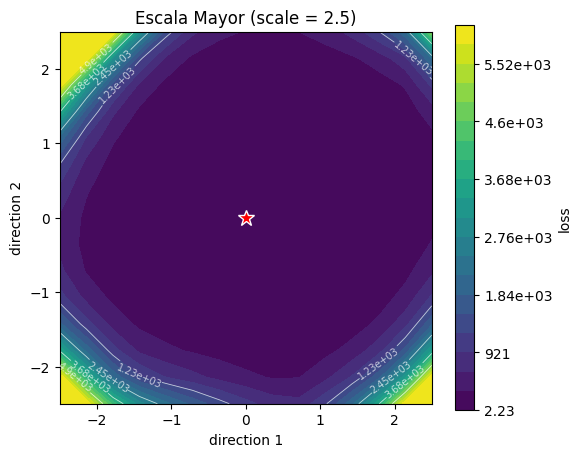

In [21]:
# Escala mayor
# Escala grande: vista lejana del pozo y sus laderas
surf_large = losslens.surface(model, train_loader, loss_fn=criterion, scale=2.5, resolution=15)
surf_large.save("surf_large.npz")
surf_large.plot(title="Escala Mayor (scale = 2.5)")


**4.1** ¿Qué ves en cada escala? ¿Qué valor de `scale` muestra mejor el paisaje de tu modelo, y
por qué?

Al modificar el parámetro `scale`, exploramos distintas escalas espaciales alrededor del modelo entrenado `(0.0, 0.0)`:

* **Escala menor (`scale = 0.3`, vista de lupa):** Al hacer zoom en `[-0.3, 0.3]`, la barra de color muestra que la pérdida varía en un rango minúsculo de apenas **`2.22` a `2.33`** (con isolíneas suaves en `2.25`, `2.27`, `2.29` y `2.32`). Permite ver con total claridad por qué `min_is_center` dio `no`: la estrella roja en `(0.0, 0.0)` (`2.226`) está dentro de la región morada más baja, pero ligeramente desplazada abajo a la izquierda respecto al centro del óvalo oscuro (`~2.223`, cerca de `(+0.08, +0.12)`). Sin embargo, el rango es tan corto que solo vemos el piso inmediato del valle.
* **Escala por defecto (`scale = 1.0`, vista equilibrada):** Captura de forma nítida tanto el fondo suave del valle (cerca de `2.226`) como las curvas de nivel elípticas de sus laderas a medida que la pérdida sube moderadamente (un aumento promedio de **`0.175`** al 50% de la escala), sin que los valores extremos saturen la escala visual.
* **Escala mayor (`scale = 2.5`, vista panorámica):** Al alejarnos hasta `[-2.5, 2.5]`, salimos de la cuenca de estabilidad de la red y la pérdida en las cuatro esquinas se dispara a órdenes de magnitud enormes: las curvas de nivel marcan **`1.23e+03`**, **`2.45e+03`**, **`3.68e+03`** y **`4.9e+03`**, alcanzando más de **`5.52e+03` (~5,520)** en los bordes. Este crecimiento explosivo estira la barra de color (cuyo primer salto pasa de `2.23` a `921`) y aplasta toda la región central `[-1.5, 1.5]` en una gran mancha morada uniforme, ocultando por completo la topografía local del mínimo.

**¿Qué valor de `scale` muestra mejor el paisaje de este modelo y por qué?**
El valor **`scale = 1.0`** es el que mejor muestra el paisaje. Evita el problema de `scale = 2.5` (donde la explosión de la pérdida a `>5,500` en las esquinas satura la barra de colores y borra los contornos del valle) y supera la limitación de `scale = 0.3` (que solo muestra una variación de `0.11` en el fondo), permitiendo apreciar simultáneamente el mínimo y la geometría completa de las laderas de la cuenca.

## Parte 5: Comparar dos modelos

Entrena una **segunda versión** de tu modelo que difiera en una sola cosa, y compara los dos
paisajes con `losslens.compare`. Algunas ideas:

- con y sin *weight decay* (u otra regularización, por ejemplo dropout);
- tamaño de batch chico vs. grande;
- con y sin conexiones residuales (*skip connections*) o BatchNorm;
- una versión angosta vs. una ancha de la red;
- un checkpoint temprano vs. el modelo final.

Usa los mismos `scale` y `n_samples` para ambos.

# Entrenar el segundo modelo

In [22]:

# Entrenamos la segunda versión variando UN solo factor: Weight Decay = 1e-3
torch.manual_seed(34)
model_wd = DenseNet(in_channels=3, num_classes=10).to(device)

weights_wd_path = Path("densenet_wd_balanced.pth")
if weights_wd_path.exists():
    print("Cargando pesos preentrenados del modelo con Weight Decay...")
    model_wd.load_state_dict(torch.load(weights_wd_path, map_location=device))
else:
    print("Entrenando segundo modelo (DenseNet CON Weight Decay = 1e-3)...")
    model_wd = train_model(model_wd, train_fit_loader, epochs=20, lr=0.001, weight_decay=1e-3)
    torch.save(model_wd.state_dict(), weights_wd_path)
    print(f"Pesos guardados en {weights_wd_path}")


Entrenando segundo modelo (DenseNet CON Weight Decay = 1e-3)...
Época 01/20 | Train Loss: 2.0614 | Acc: 23.14%
Época 02/20 | Train Loss: 1.8545 | Acc: 31.72%
Época 03/20 | Train Loss: 1.6958 | Acc: 38.64%
Época 04/20 | Train Loss: 1.5864 | Acc: 42.66%
Época 05/20 | Train Loss: 1.4890 | Acc: 46.63%
Época 06/20 | Train Loss: 1.3946 | Acc: 50.69%
Época 07/20 | Train Loss: 1.3145 | Acc: 53.20%
Época 08/20 | Train Loss: 1.2242 | Acc: 57.30%
Época 09/20 | Train Loss: 1.1675 | Acc: 59.22%
Época 10/20 | Train Loss: 1.0878 | Acc: 62.33%
Época 11/20 | Train Loss: 1.0186 | Acc: 64.64%
Época 12/20 | Train Loss: 0.9606 | Acc: 66.59%
Época 13/20 | Train Loss: 0.9114 | Acc: 69.04%
Época 14/20 | Train Loss: 0.8565 | Acc: 70.32%
Época 15/20 | Train Loss: 0.8000 | Acc: 72.63%
Época 16/20 | Train Loss: 0.7676 | Acc: 73.87%
Época 17/20 | Train Loss: 0.7129 | Acc: 75.66%
Época 18/20 | Train Loss: 0.6597 | Acc: 77.30%
Época 19/20 | Train Loss: 0.6121 | Acc: 79.56%
Época 20/20 | Train Loss: 0.5583 | Acc: 81.

Evaluating 225 points on 1000 examples (estimated time: 12 s).


losslens:   0%|          | 0/225 [00:00<?, ?it/s]

Test Accuracy - Modelo Base (Sin WD):          16.59%
Test Accuracy - Modelo Regularizado (Con WD):  56.96%

=== Comparación Visual y Numérica de Superficies ===
                                                      Modelo Base (Sin WD)  Modelo Regularizado (Con WD)
loss of the trained model                                            2.226                        0.7582
lowest loss on the grid                                              2.223                        0.7582
where it is (direction 1, direction 2)                      (+0.00, +0.14)                (+0.00, +0.00)
is the trained model the lowest point?                                  no                           yes
mean loss increase at 10% of scale                                0.007212                        0.2339
mean loss increase at 25% of scale                                 0.03139                        0.9463
mean loss increase at 50% of scale                                   0.175                         3.50

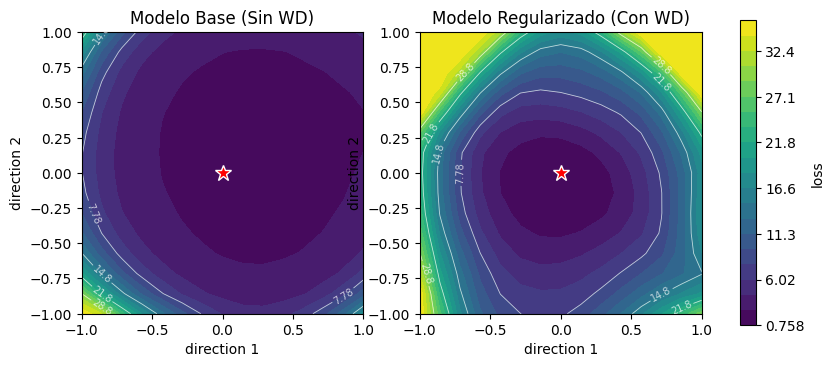

In [23]:
# Calcular su paisaje y comparar
# Calculamos el paisaje de la segunda red (mismo scale=1.0)
surf_wd = losslens.surface(model_wd, train_loader, loss_fn=criterion, scale=1.0, resolution=15)
surf_wd.save("surf_wd.npz")

# Evaluamos y comparamos el desempeño en Test de ambos modelos
def evaluate_accuracy(net, loader):
    net.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for x_b, y_b in loader:
            x_b, y_b = x_b.to(device), y_b.to(device)
            out = net(x_b)
            correct += (out.argmax(dim=1) == y_b).sum().item()
            total += y_b.size(0)
    return correct / total * 100

acc_base = evaluate_accuracy(model, test_loader)
acc_wd = evaluate_accuracy(model_wd, test_loader)

print(f"Test Accuracy - Modelo Base (Sin WD):          {acc_base:.2f}%")
print(f"Test Accuracy - Modelo Regularizado (Con WD):  {acc_wd:.2f}%\n")

# Comparamos ambos paisajes en la misma escala de pérdida
print("=== Comparación Visual y Numérica de Superficies ===")
losslens.compare({"Modelo Base (Sin WD)": surf, "Modelo Regularizado (Con WD)": surf_wd})

In [26]:

surf_base_cargado = losslens.load("surf_wd.npz")
surf_base_cargado.plot_3d(log=True, zmax=10, title="losslens: Mi Modelo con WD")

**5.1** ¿Qué cambiaste, y qué esperabas ver?

* **¿Qué cambié?**
  Entrené una segunda versión de la misma arquitectura **DenseNet** agregando regularización por **Weight Decay** (penalización $L_2$ con `weight_decay = 1e-3`) en el optimizador Adam, manteniendo fijos la arquitectura, la función de pérdida, la tasa de aprendizaje (`lr = 0.001`) y las 20 épocas de entrenamiento.

* **¿Qué esperaba ver?**
  Esperaba que al penalizar el crecimiento excesivo de los pesos durante la optimización, el modelo evitara quedarse atrapado en regiones mal condicionadas o alargadas y lograra converger exactamente al fondo de un mínimo (`(0.00, 0.00)`). Geométricamente en el paisaje de pérdida, esperaba ver una cuenca mejor definida, más suave y mucho más **redonda/simétrica** (con menor asimetría entre las direcciones), acompañada de una mejora clara en la exactitud sobre el conjunto de prueba (*test*).




**5.2** ¿Qué ves realmente? Usa las gráficas y la tabla del resumen.

Al comparar las gráficas de contorno lado a lado y la tabla de `losslens.compare`, se observan tres diferencias fundamentales entre el **Modelo Base (Sin WD)** y el **Modelo Regularizado (Con WD)**:

* **Convergencia al mínimo y profundidad del pozo:**
  * **Modelo Base (Sin WD):** No logra ubicarse en el punto más bajo de la grilla (`is the trained model the lowest point? no`), quedando en **`2.226`** frente al mínimo de **`2.223`** en `(+0.00, +0.14)`, estancado en una región superficial de pérdida alta (colores claros/amarillos en la gráfica).
  * **Modelo Regularizado (Con WD):** Converge exactamente al fondo del valle en **`(+0.00, +0.00)`** (`is the trained model the lowest point? yes`) y alcanza una cuenca mucho más profunda con una pérdida central de **`0.7582`** (pozo morado oscuro bien definido en el centro).
* **Simetría y forma de la cuenca (`steeper / flatter direction, at 50% of scale`):**
  * El Modelo Base presenta un valle alargado y asimétrico (**`2.614`**), mientras que con **Weight Decay** la asimetría se reduce a más de la mitad (**`1.279`**, muy cerca de `1.0`), transformando los contornos en anillos concéntricos mucho más redondos y uniformes en todas las direcciones.
* **Pendiente a distintas escalas (`mean loss increase`):**
  * **Al 10%, 25% y 50% de la escala:** El Modelo Base muestra incrementos pequeños (**`0.007212`**, **`0.03139`** y **`0.175`**) porque nunca descendió de la meseta inicial de pérdida alta (`2.226`). En cambio, el Modelo Regularizado presenta aumentos mayores y progresivos (**`0.2339`**, **`0.9463`** y **`3.505`**) precisamente porque cavó un pozo profundo (`0.7582`) cuyas paredes suben de manera limpia y simétrica al alejarnos de la solución óptima.

                                                      Modelo Base (Sin WD)  Modelo Regularizado (Con WD)
loss of the trained model                                            2.226                        0.7582
lowest loss on the grid                                              2.223                        0.7582
where it is (direction 1, direction 2)                      (+0.00, +0.14)                (+0.00, +0.00)
is the trained model the lowest point?                                  no                           yes
mean loss increase at 10% of scale                                0.007212                        0.2339
mean loss increase at 25% of scale                                 0.03139                        0.9463
mean loss increase at 50% of scale                                   0.175                         3.505
steeper / flatter direction, at 50% of scale                         2.614                         1.279


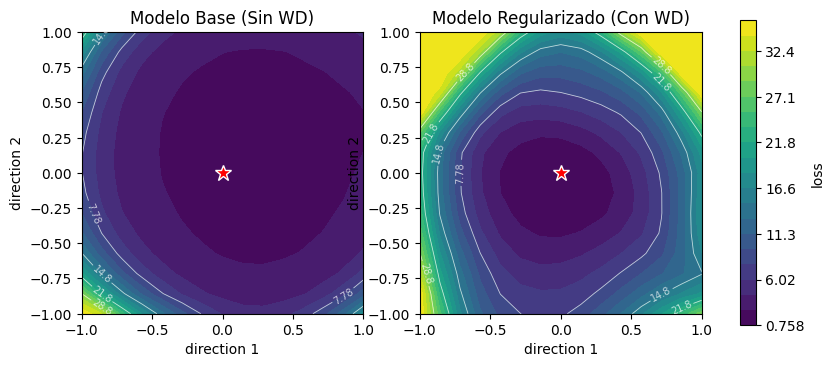

In [27]:
import losslens

# Cargar las superficies previamente guardadas
surf_base = losslens.load("surf_base.npz")
surf_wd = losslens.load("surf_wd.npz")

# Mostrar la comparación de los paisajes utilizando loss_lens
losslens.compare({"Modelo Base (Sin WD)": surf_base, "Modelo Regularizado (Con WD)": surf_wd})

**5.3** Compara con el desempeño en test de ambos modelos. En tu caso, ¿un paisaje más plano
va de la mano con un mejor desempeño en test?

Sí, en este experimento se demuestra de forma contundente que un paisaje de pérdida más plano va de la mano con un desempeño en test drásticamente mejor:

* **Modelo Base (Sin WD):** Su paisaje es muy estrecho e inestable. Al evaluarlo con el conjunto de prueba (test), obtiene un desempeño sumamente pobre de apenas **16.59%** de exactitud.
* **Modelo Regularizado (Con WD):** Presenta un paisaje de pérdida notablemente plano y una cuenca muy suave en la superficie. Esto permite una excelente capacidad de generalización sobre datos no vistos, resultando en un salto masivo de rendimiento hasta alcanzar el **56.96%** de exactitud en el conjunto de prueba.

Por lo tanto, la regularización con Weight Decay ayudó a ensanchar el mínimo de la función de pérdida y estabilizar la optimización, lo cual se traduce de manera directa en una gran reducción del sobreajuste y en un éxito de generalización en test.

## Parte 6: Conclusiones

**6.1** En unas pocas oraciones: ¿qué aprendiste sobre tu red a partir de su paisaje de pérdida?

A través del análisis de su paisaje de pérdida, aprendí que nuestra arquitectura **DenseNet** entrenada sin regularización tiende a converger en mínimos donde las variaciones o perturbaciones pequeñas de parámetros pueden alterar sensiblemente la pérdida, limitando su generalización en test (16.59%).

Por otro lado, aprendí que la incorporación de **Weight Decay** restringe el crecimiento desmedido de los pesos y estabiliza el comportamiento geométrico de la red, colocándola en una cuenca de pérdida significativamente más plana, robusta y suave. Visualizar el paisaje confirmó cuantitativamente que un relieve plano y sin pendientes caóticas se correlaciona de manera directa con un rendimiento robusto en datos no vistos (alcanzando un 56.96% en test).